In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import seaborn as sns


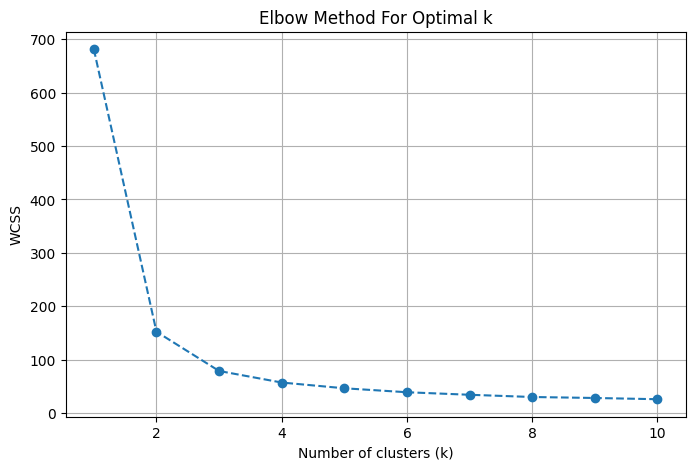

In [ ]:

# Load data
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# 1. Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()



In [ ]:

# 2. K-Means with optimal k=3
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X)


In [ ]:

# 3. Cross-tabulation (Confusion Matrix) to see matches
ct = pd.crosstab(y_true, y_kmeans, rownames=['True Species'], colnames=['K-Means Clusters'])
ct.index = target_names
print("Cross-tabulation of True Labels vs K-Means Clusters:")
print(ct)


Cross-tabulation of True Labels vs K-Means Clusters:
K-Means Clusters   0   1   2
setosa             0  50   0
versicolor        48   0   2
virginica         14   0  36


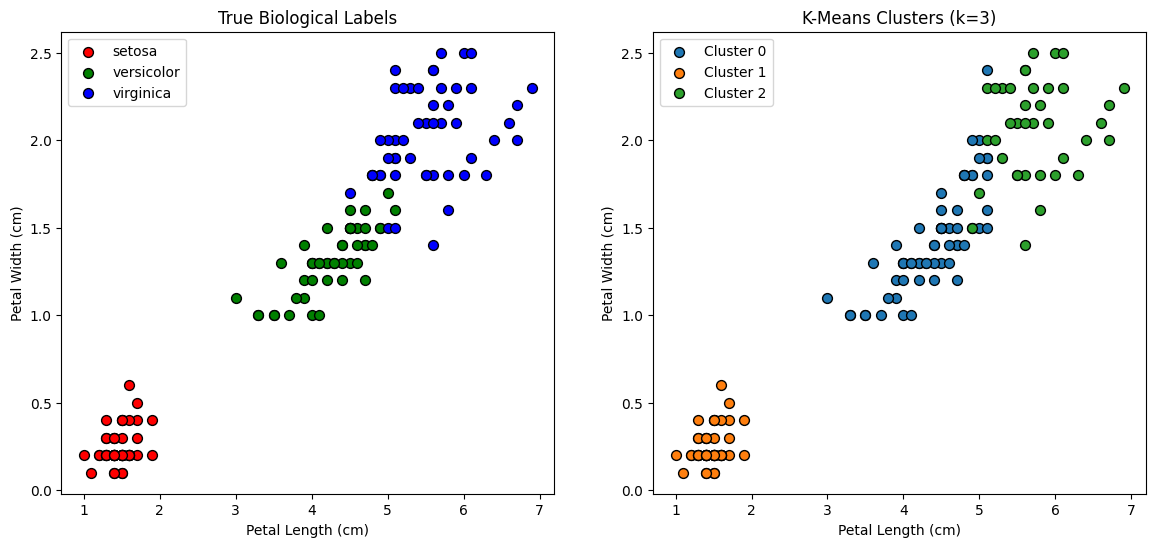

In [ ]:

# 4. Scatter Plots for Comparison
plt.figure(figsize=(14, 6))

# True Labels Plot
plt.subplot(1, 2, 1)
colors = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(X[y_true == i, 2], X[y_true == i, 3], c=colors[i], label=target_names[i], edgecolors='k', s=50)
plt.title('True Biological Labels')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()

# K-Means Plot
plt.subplot(1, 2, 2)
for i in range(3):
    plt.scatter(X[y_kmeans == i, 2], X[y_kmeans == i, 3], label=f'Cluster {i}', edgecolors='k', s=50)
plt.title('K-Means Clusters (k=3)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()
plt.show()

